# Classical learning benchmark: a controlled comparison from implementation to claim

## 1. Introduction and learning objectives

This capstone compares inductive biases under one declared data-use protocol. A large leaderboard is not the goal. You must explain why a model represents a task, implement its essential computation, verify mathematical and procedural correctness independently, and evaluate a frozen comparison with honest limits. Reuse your own verified study implementations; all author references remain separately collapsed.

Complete the seven [Stage 02 chapters](../../notebooks/02-classical-ml/README.md) and Stage 01 evaluation first. Read [project instructions](README.md) and copy the [report template](report-template.md) to your study branch. Required work uses manual NumPy models, generated regression/binary data, and the bundled licensed Iris data. No download, GPU, framework or new dependency is required.

**Deliverables:** a protocol fixed before final test access; working models and independent checks; every candidate's fold record, validation decisions and optimizer status; numeric checkpoints; one frozen final evaluation; resource measurements; and a bounded technical report. Research practice means stating what these experiments support and what they cannot establish about other datasets or modern AI systems.

## 2. Prerequisites and mathematical foundations

Features are row-wise $(n,d)$ arrays. Regression targets have shape $(n,)$. Classification uses sorted integer classes and probability columns in that order. The primary metric is unpenalized MSE for regression and error rate for classification. Secondary metrics include MAE/RMSE, confusion counts and macro recall, and log loss/Brier **only for models that actually return probabilities**. A raw SVM or one-versus-rest boosting score is not silently converted into a calibrated probability.

Required regression families are training-mean baseline, ridge, nearest neighbors, tree, forest and squared-loss boosting. Required classifiers are training-prevalence baseline, linear softmax, nearest neighbors, shared/diagonal Gaussian models, tree, forest, one-versus-rest logistic boosting and one-versus-rest kernel SVM. The capstone carries earlier displayed definitions into its reference text so it executes independently; no reference-model answers enter the reusable package.

### Fixed data and selection protocol

1. Generate regression (180 rows, seed 240) and balanced radial binary classification (160 rows, seed 241); load Iris (150 rows, four centimeter-valued features) from the exact bundled UCI artifact.
2. Group identical feature vectors before partitioning. The unchanged Iris artifact has 147 distinct feature vectors, including a three-row and a two-row duplicate group. Keep every group's rows together. Do not silently correct source discrepancies or drop duplicates.
3. Seed 242 assigns approximately 60/20/20 percent of **groups** to training/validation/test, separately by class for classification. Regression has 108/36/36 rows and radial classification 96/32/32. Iris row counts can differ from exact 90/30/30 because group sizes differ; report actual counts.
4. Use three group-preserving folds within training only (seed 243). Every non-baseline family gets exactly two predeclared candidates. Fit scaling on each fold's training rows, then transform its held-out rows. Pool held-out observation losses, weighting unequal fold sizes correctly. Ties use candidate order.
5. Refit each family's CV winner on the complete training partition only, with a training-only scaler. Use validation once to select the primary family. Keep the training baseline in every panel. Do not refit on validation rows.
6. Freeze the per-family configurations, validation-selected champion, metric conventions and resource budgets. Save numeric selection evidence. Evaluate all these already frozen models in **one final test batch**. Do not choose a new champion from the test panel.
7. Report the predeclared champion-versus-baseline paired loss difference with a group-resampling sensitivity interval. It is conditional on the fitted models and split, and does not include training/selection uncertainty or guarantee field-population coverage.

Every method receives the same observations and fold assignments for its task. Equal candidate counts control selection opportunities; they do **not** imply equal wall time, arithmetic, model capacity or optimization accuracy. Report those differences rather than asserting a stronger fairness claim.

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 02.P.01 — Freeze a reviewable comparison protocol

**Type:** Conceptual · **Answer:** Markdown

Write your tasks, data versions, group/split seeds, primary/secondary metrics, candidate grids, stopping budgets, tie rules, validation decision and final-test boundary before measuring performance. Explain why identical splits alone do not establish a universal fair algorithm comparison.

**Expected outcome:** a concrete protocol and a list of quantities that remain unmatched or uncertain.

**Your response to Exercise 02.P.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.P.01**

Name the exact objective/representation and work budget for each family, not just its model label.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.P.01**

Use the ordered protocol and grids below as the required baseline. Shared splits, preprocessing boundaries and candidate counts remove several avoidable differences. The families still differ in expressive power, operation count, numerical conditioning and stopping quality; SVM gaps and linear-gradient diagnostics must remain visible. The validation-selected family is fixed before a single test batch, and the test panel is descriptive rather than another selection grid. A claim should name these data, algorithms, seeds and budgets. It cannot establish a universal ranking, deployment quality or causality from one small historical dataset and two synthetic mechanisms.

</details>

## 3. Theoretical development and worked examples

### Normalize objectives before comparing learners

Ridge minimizes $\|Xw+b-y\|^2/(2n)+\lambda\|w\|^2/2$, with unpenalized bias. Linear softmax minimizes average categorical log loss plus $\lambda\|W\|_F^2/2$, also leaving the bias vector unpenalized. Their derivatives must average the observation loss once. The SVM references use canonical $\|w\|^2/2+C\sum_i\mathrm{hinge}_i$; this capstone supplies $C=1/(n\lambda)$ to retain the mean-loss interpretation when fold sizes change.

Tree/forest split losses and the booster's training objectives need not equal the evaluation metric. Boosting fits first-order residual trees with declared stage budgets; its binary one-versus-rest logits are used as decision scores. The SVM projected solver returns an actual gap and convergence flag. Do not describe a budget-limited run as an objective optimum or substitute a surrogate gap for zero-one error.

For $K$ classes, one-versus-rest SVM uses binary labels $y_i^{(c)}=+1$ when $y_i=c$ and $-1$ otherwise; logistic boosting uses targets $1[y_i=c]$. Train these $K$ problems independently and predict $\arg\max_c f_c(x)$, resolving ties by sorted class order. Independent fits need not yield mutually normalized or comparable probability estimates; raw maximum-score selection is the explicit multiclass decision construction used here. Softmax instead fits one jointly normalized categorical model.

Frequency-based probability models (neighbors, trees, forests) use a predeclared $5\%$ mixture with uniform class probabilities: $p'= .95p+.05/K$. This changes their reported probability estimator, avoids unannounced zero-probability floors, and preserves hard argmax decisions. It is not evidence of calibration. Gaussian and softmax log posteriors are retained directly so numerical probability underflow does not discard a finite log loss. SVM/boosting probability metrics are explicitly unavailable.

### Compare paired losses at the right unit

For fixed predictors $A,B$, define per-row difference $d_i=\ell_A(i)-\ell_B(i)$ using MSE contributions or error indicators. The observed mean difference is $\bar d$. Negative values favor $A$ for that metric. Resample complete groups with the **same** sampled indices for both methods; retain all rows of each sampled group and recompute the pooled row mean. Group size affects the denominator. Do not average unequal group means as if that were the same row-weighted estimand.

**Hand example:** baseline squared losses $(4,0,1,1)$ and model losses $(1,1,0,0)$ give differences $(-3,1,-1,-1)$ and mean $-1$. Groups $(0,0,1,2)$ have total differences $(-2,-1,-1)$ and sizes $(2,1,1)$. A resample of groups $(0,0,1)$ has numerator $-5$, denominator $5$, and difference $-1$. This is a conditional resampling calculation, not proof that the model wins in every population.

### Exercise 02.P.02 — Derive the baselines, linear gradients and comparison target

**Type:** Mathematical · **Answer:** Markdown

Derive the training mean for squared loss, empirical class proportions for categorical log loss, ridge normal equations with unpenalized bias, and softmax weight/bias gradients. Explain the SVM $C$ conversion and the estimand of the paired group comparison.

**Expected outcome:** explicit objectives, shapes and denominators, plus a distinction between predictive metrics and training surrogates.

**Your response to Exercise 02.P.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.P.02**

Augment features with one constant column and use a penalty matrix whose last diagonal entry is zero.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.P.02**

The mean minimizes training SSE by completing the square. Empirical proportions minimize categorical log loss by its entropy/KL decomposition. For $Z=[X,\mathbf1]$, ridge solves $(Z^TZ/n+\lambda D)\theta=Z^Ty/n$ with $D=\mathrm{diag}(1,\ldots,1,0)$. Softmax sensitivity is $(P-Y)/n$, so $\nabla_W=X^T(P-Y)/n+\lambda W$ and $\nabla_b=\sum_i(P_i-Y_i)/n$. Multiplying the mean hinge objective by $1/\lambda$ gives canonical $C=1/(n\lambda)$. The paired comparison is a row-weighted mean loss difference for two frozen procedures on the realized test partition, with group resampling modeling exchangeable groups conditionally. It does not include a new training-set draw or establish a universal algorithm ranking.

</details>

### Exercise 02.P.03 — Audit weighting and probability conventions

**Type:** Numerical · **Answer:** Markdown

Reproduce the paired hand calculation. Two CV folds have sizes two and three, with candidate A error rates $.5,0$ and candidate B rates $0,1/3$. Calculate pooled errors and the deterministic winner if A is listed first. For a three-class frequency vector $(1,0,0)$, calculate the declared mixture and explain why its log loss differs from raw frequencies.

**Expected outcome:** paired difference $-1$, pooled CV tie at $.2$ selecting A, and mixture $(29/30,1/60,1/60)$.

**Your response to Exercise 02.P.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.P.03**

Weight fold means by held-out row count. The uniform mixture adds $.05/3$ to each component after multiplying the original vector by $.95$.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.P.03**

The four paired differences sum to $-4$, so their mean is $-1$. Both candidates make one mistake among five held-out observations, giving $.2$ each; grid order selects A. Unweighted fold means would be $.25$ versus $1/6$ and incorrectly select B for this pooled metric. The mixture is $(.95+.05/3,.05/3,.05/3)=(29/30,1/60,1/60)$. It avoids zero forecasts by an explicit alternative probability model, whose probability losses must be labeled accordingly. It does not improve empirical hard decisions in this example or certify calibration.

</details>

## 4. Guided exercises

### Exercise 02.P.04 — Construct deterministic tasks and group-preserving partitions

**Type:** Programming · **Answer:** Code

Implement `benchmark_datasets`, `benchmark_partition` and the supporting group-stratum checks. Keep exact duplicate feature rows together, stratify group allocation by class, preserve all records and record actual sizes. Reject mixed-class duplicate groups in this simple stratification scheme rather than splitting them. Use synthetic targets only to generate the task, not to fit preprocessing or select using test data.

**Expected outcome:** deterministic disjoint/exhaustive row partitions, no group overlap, source identity and correctly reported class counts.

In [ ]:
# Your code for Exercise 02.P.04.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.P.04**

Assign whole group IDs to partitions; then recover their original row indices. Grouping is a split-design step, not a fitted feature transform.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.P.04**

This uses only the packaged data loader, which supplies no model answers. The source's known discrepancies and duplicates are retained. The split helper accepts targets/groups and a named task, and uses class labels only for the declared stratification. It does not promise exact row ratios for unequal-size groups.

~~~python
from ml_from_scratch.datasets import load_iris

def benchmark_datasets():
    rng = np.random.default_rng(240)
    X = rng.normal(size=(180,4))
    regression = dict(task='regression',X=X,y=np.sin(2*X[:,0])+.3*X[:,1]+rng.normal(0,.2,180),groups=np.arange(180))
    rng = np.random.default_rng(241)
    y = np.repeat([0,1],80)
    radius = np.repeat([.7,1.5],80)+rng.normal(0,.12,160)
    angle = rng.uniform(-np.pi,np.pi,160)
    X = np.column_stack([radius*np.cos(angle),radius*np.sin(angle),rng.normal(0,.3,size=(160,2))])
    order = rng.permutation(160)
    radial = dict(task='classification',X=X[order],y=y[order],groups=np.arange(160))
    X,y = load_iris(); _,groups = np.unique(X,axis=0,return_inverse=True)
    iris = dict(task='classification',X=X,y=y,groups=groups)
    return dict(regression=regression,radial=radial,iris=iris)

def benchmark_group_strata(targets, groups, task):
    y = np.asarray(targets); groups = np.asarray(groups)
    if y.ndim != 1 or len(y) == 0 or groups.shape != y.shape or not np.isfinite(y).all() or not np.issubdtype(groups.dtype,np.integer):
        raise ValueError('finite target vector and compatible integer groups required')
    if task not in ('regression','classification') or (task == 'classification' and not np.issubdtype(y.dtype,np.integer)):
        raise ValueError('known task and integer classification labels required')
    strata = {}
    for group in np.unique(groups):
        labels = np.unique(y[groups == group])
        if task == 'classification' and len(labels) != 1:
            raise ValueError('this stratification requires one class per group')
        stratum = int(labels[0]) if task == 'classification' else 0
        strata.setdefault(stratum,[]).append(int(group))
    return y,groups,strata

def benchmark_partition(targets, groups, task, seed=242):
    _,groups,strata = benchmark_group_strata(targets,groups,task)
    rng = np.random.default_rng(seed); allocated = [[],[],[]]
    for label in sorted(strata):
        order = rng.permutation(strata[label]); n = len(order)
        a,b = int(.6*n),int(.2*n)
        if a < 3 or b < 1 or n-a-b < 1:
            raise ValueError('each stratum needs enough groups for train/validation/test')
        for destination,part in zip(allocated,(order[:a],order[a:a+b],order[a+b:])):
            destination.extend(part.tolist())
    return tuple(np.flatnonzero(np.isin(groups,part)) for part in allocated)

demo_tasks = benchmark_datasets()
assert benchmark_partition(demo_tasks['regression']['y'],demo_tasks['regression']['groups'],'regression')[0].shape == (108,)
~~~

</details>

### Exercise 02.P.05 — Build training-only scales and common group folds

**Type:** Programming · **Answer:** Code

Implement fold-local scaling and `benchmark_folds`. Split groups into three folds within the training partition, keeping each class represented. Store the exact indices and fit a new scaler for every fold. Test an extreme held-out feature value and verify that it cannot change the scaler fitted to the other rows.

**Expected outcome:** complete group-safe fold coverage, population-standard-deviation scaling, constant-column handling and no fitting on held-out rows.

In [ ]:
# Your code for Exercise 02.P.05.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.P.05**

Standard deviation uses divisor $n$ here. Replace a zero training scale by one; do not recompute it on a query set.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.P.05**

This depends on `benchmark_group_strata`. Every family's candidates receive the same fold list, but a fresh scaler is fit from each fold's training rows. The final family refits later receive a new complete-training scaler; validation/test rows are never included in those statistics.

~~~python
def benchmark_folds(targets, groups, task, folds=3, seed=243):
    _,groups,strata = benchmark_group_strata(targets,groups,task)
    if isinstance(folds,(bool,np.bool_)) or not isinstance(folds,(int,np.integer)) or folds < 2:
        raise ValueError('integer fold count at least two required')
    rng = np.random.default_rng(seed); held_groups = [[] for _ in range(folds)]
    for label in sorted(strata):
        if len(strata[label]) < folds:
            raise ValueError('every stratum needs at least one group per fold')
        for destination,part in zip(held_groups,np.array_split(rng.permutation(strata[label]),folds)):
            destination.extend(part.tolist())
    result = []
    for part in held_groups:
        mask = np.isin(groups,part)
        result.append((np.flatnonzero(~mask),np.flatnonzero(mask)))
    return result

def benchmark_scale_fit(X):
    X = np.asarray(X,dtype=float)
    if X.ndim != 2 or min(X.shape) == 0 or not np.isfinite(X).all():
        raise ValueError('finite nonempty feature matrix required')
    with np.errstate(over='raise',invalid='raise'):
        mean = X.mean(axis=0); scale = X.std(axis=0,ddof=0)
    if not np.isfinite(mean).all() or not np.isfinite(scale).all():
        raise FloatingPointError('training scales are outside finite range')
    scale[scale == 0] = 1.
    return dict(mean=mean,scale=scale)

def benchmark_scale_apply(X, scaler):
    X = np.asarray(X,dtype=float)
    if X.ndim != 2 or X.shape[1:] != scaler['mean'].shape or not np.isfinite(X).all():
        raise ValueError('finite compatible feature matrix required')
    with np.errstate(over='raise',invalid='raise',divide='raise'):
        return (X-scaler['mean'])/scaler['scale']
~~~

</details>

## 5. Implementation challenges

Run hand/gradient checks before selection. Later solution snippets refer only to definitions displayed earlier in this capstone. The copied model definitions are the already authored Stage 02 references, included here as text for portability. They retain their input validation, numeric conventions and bounded-work limitations. Learners should adapt their own implementations and compare them with independent checks.

### Exercise 02.P.06 — Implement constant and linear baselines

**Type:** Programming · **Answer:** Code

Implement ridge and a manually differentiated multiclass softmax model. Ridge uses a linear solve; softmax uses 600 full-batch steps with a declared spectral step bound, fixed parameters and no autodiff. Record the final gradient norm and training-loss trace. Verify all weights and bias coordinates against independently written objectives before evaluating any held-out performance.

**Expected outcome:** unpenalized biases, mean-loss scaling, row-duplication checks, stable log probabilities and explicit optimizer diagnostics.

In [ ]:
# Your code for Exercise 02.P.06.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.P.06**

The softmax Hessian's largest categorical eigenvalue is at most $1/2$. Augmenting $X$ with a constant gives a conservative shared step bound including the bias.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.P.06**

These functions introduce the capstone's small linear baselines; they do not call the package for solutions. The spectral bound is $\|[X,1]\|_2^2/(2n)+\lambda$ for this joint parameter norm. A fixed iteration count is reported as a work budget, with final gradient norm rather than an automatic claim of exact convergence.

~~~python
def benchmark_ridge_fit(X, targets, penalty):
    X = np.asarray(X,dtype=float); y = np.asarray(targets,dtype=float)
    if X.ndim != 2 or min(X.shape) == 0 or y.shape != (len(X),) or not np.isfinite(X).all() or not np.isfinite(y).all() or not np.isfinite(penalty) or penalty < 0:
        raise ValueError('finite compatible training arrays and nonnegative penalty required')
    Z = np.column_stack([X,np.ones(len(X))]); D = np.eye(Z.shape[1]); D[-1,-1] = 0
    with np.errstate(over='raise',invalid='raise'):
        theta = np.linalg.solve(Z.T@Z/len(X)+penalty*D,Z.T@y/len(X))
        gradient = Z.T@(Z@theta-y)/len(X)+penalty*(D@theta)
    return dict(weights=theta[:-1],bias=float(theta[-1]),gradient_norm=float(np.linalg.norm(gradient)))

def benchmark_log_probabilities(logits):
    logits = np.asarray(logits,dtype=float)
    if logits.ndim != 2 or logits.shape[1] == 0 or not np.isfinite(logits).all():
        raise ValueError('finite logit matrix required')
    if len(logits) == 0:
        return logits.copy()
    with np.errstate(over='raise',invalid='raise'):
        shifted = logits-logits.max(axis=1,keepdims=True)
        return shifted-np.log(np.exp(shifted).sum(axis=1,keepdims=True))

def benchmark_softmax_objective(X, labels, weights, bias, penalty):
    X = np.asarray(X,dtype=float); y = np.asarray(labels)
    W = np.asarray(weights,dtype=float); b = np.asarray(bias,dtype=float)
    if X.ndim != 2 or min(X.shape) == 0 or W.ndim != 2 or W.shape[0] != X.shape[1] or W.shape[1] < 2 or b.shape != (W.shape[1],) or y.shape != (len(X),) or not np.issubdtype(y.dtype,np.integer) or np.any((y < 0)|(y >= W.shape[1])):
        raise ValueError('compatible features, encoded labels and multiclass parameters required')
    if not all(np.isfinite(a).all() for a in (X,W,b)) or not np.isfinite(penalty) or penalty < 0:
        raise ValueError('finite parameters and nonnegative penalty required')
    with np.errstate(over='raise',invalid='raise'):
        logp = benchmark_log_probabilities(X@W+b); p = np.exp(logp)
        value = -logp[np.arange(len(X)),y].mean()+penalty*np.sum(W*W)/2
        sensitivity = p.copy(); sensitivity[np.arange(len(X)),y] -= 1; sensitivity /= len(X)
        return float(value),X.T@sensitivity+penalty*W,sensitivity.sum(axis=0)

def benchmark_softmax_fit(X, labels, penalty, steps=600):
    X = np.asarray(X,dtype=float); y = np.asarray(labels)
    classes = np.unique(y)
    if not np.array_equal(classes,np.arange(len(classes))) or len(classes) < 2:
        raise ValueError('consecutive encoded classes with all classes observed required')
    if isinstance(steps,(bool,np.bool_)) or not isinstance(steps,(int,np.integer)) or steps < 1:
        raise ValueError('positive integer step count required')
    W = np.zeros((X.shape[1],len(classes))); b = np.zeros(len(classes))
    benchmark_softmax_objective(X,y,W,b,penalty)
    Z = np.column_stack([X,np.ones(len(X))])
    with np.errstate(over='raise',invalid='raise'):
        curvature = np.linalg.norm(Z,ord=2)**2/(2*len(X))+penalty
    if not np.isfinite(curvature) or curvature <= 0:
        raise FloatingPointError('spectral step bound is outside finite range')
    rate = 1/curvature
    history = []
    for _ in range(steps):
        value,dW,db = benchmark_softmax_objective(X,y,W,b,penalty)
        history.append(value); W -= rate*dW; b -= rate*db
    value,dW,db = benchmark_softmax_objective(X,y,W,b,penalty); history.append(value)
    return dict(weights=W,bias=b,loss_history=np.array(history),iterations=int(steps),
                gradient_norm=float(np.sqrt(np.sum(dW*dW)+np.sum(db*db))))
~~~

</details>

### Exercise 02.P.07 — Integrate neighborhood and Gaussian families

**Type:** Programming · **Answer:** Code

Bring your verified nearest-neighbor regression/classification and Gaussian shared/diagonal classifiers into this notebook. Preserve distance/vote tie rules, log-domain scoring, empirical covariance divisors and explicit positive jitter. Compare tiny predictions with scalar calculations before wiring the benchmark adapter.

**Expected outcome:** portable manual models with their numerical contracts and class-column ordering intact.

In [ ]:
# Your code for Exercise 02.P.07.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.P.07**

Do not fit scaling inside these models using query rows. The benchmark supplies already transformed train/query arrays.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.P.07**

The following are the earlier chapter definitions, copied as displayed text so no other notebook needs to execute. `knn_classify` returns its observed sorted classes; the capstone adapter later aligns these with its training encoding and explicitly mixes frequency probabilities with a fixed uniform distribution.

~~~python
def neighbor_features(train, query):
    train, query = np.asarray(train, float), np.asarray(query, float)
    if train.ndim != 2 or min(train.shape) == 0 or query.ndim != 2 or query.shape[1] != train.shape[1]:
        raise ValueError("nonempty training rows and matching query feature width required")
    if not np.isfinite(train).all() or not np.isfinite(query).all():
        raise ValueError("finite features required")
    return train, query

def neighbor_search(train, query, k, query_block=32, train_block=128):
    train, query = neighbor_features(train, query)
    for value in (k, query_block, train_block):
        if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value < 1:
            raise ValueError("positive integer k and block sizes required")
    if k > len(train):
        raise ValueError("k cannot exceed training size")
    result_indices = np.empty((len(query), k), dtype=int)
    result_distances = np.empty((len(query), k))
    for start in range(0, len(query), query_block):
        Q = query[start:start+query_block]
        best_d, best_i = np.empty((len(Q), 0)), np.empty((len(Q), 0), dtype=int)
        for offset in range(0, len(train), train_block):
            T = train[offset:offset+train_block]
            distance = np.zeros((len(Q), len(T)))
            with np.errstate(over='ignore', invalid='ignore'):
                for j in range(train.shape[1]):
                    difference = Q[:, j, None]-T[None, :, j]
                    distance += difference*difference
            if not np.isfinite(distance).all():
                raise FloatingPointError("squared distances exceed floating-point range")
            ids = np.broadcast_to(np.arange(offset, offset+len(T)), distance.shape)
            candidates_d = np.concatenate([best_d, distance], axis=1)
            candidates_i = np.concatenate([best_i, ids], axis=1)
            order = np.lexsort((candidates_i, candidates_d), axis=1)[:, :k]
            best_d = np.take_along_axis(candidates_d, order, axis=1)
            best_i = np.take_along_axis(candidates_i, order, axis=1)
        result_indices[start:start+len(Q)] = best_i
        result_distances[start:start+len(Q)] = best_d
    return result_indices, result_distances

def neighbor_weights(squared, mode='uniform'):
    squared = np.asarray(squared, float)
    if squared.ndim != 2 or squared.shape[1] == 0 or not np.isfinite(squared).all() or np.any(squared < 0):
        raise ValueError("finite nonnegative distance matrix with k >= 1 required")
    if mode == 'uniform':
        return np.full(squared.shape, 1/squared.shape[1])
    if mode != 'distance':
        raise ValueError("unknown weighting mode")
    zero = squared == 0; exact = zero.any(axis=1)
    result = np.empty_like(squared)
    if exact.any():
        result[exact] = zero[exact]/zero[exact].sum(axis=1, keepdims=True)
    if (~exact).any():
        inverse = 1/np.sqrt(squared[~exact])
        result[~exact] = inverse/inverse.sum(axis=1, keepdims=True)
    return result

def knn_classify(train, labels, query, k, mode='uniform'):
    train, query = neighbor_features(train, query)
    labels = np.asarray(labels)
    if labels.shape != (len(train),) or not np.issubdtype(labels.dtype, np.integer):
        raise ValueError("one integer label per training row required")
    classes, encoded = np.unique(labels, return_inverse=True)
    indices, squared = neighbor_search(train, query, k)
    weights = neighbor_weights(squared, mode)
    scores = np.zeros((len(query), len(classes)))
    np.add.at(scores, (np.arange(len(query))[:, None], encoded[indices]), weights)
    prediction = classes[np.argmax(scores, axis=1)]
    return prediction, scores, classes

def knn_regress(train, targets, query, k, mode='uniform'):
    train, query = neighbor_features(train, query)
    targets = np.asarray(targets, float)
    if targets.shape != (len(train),) or not np.isfinite(targets).all():
        raise ValueError("finite target vector required")
    indices, squared = neighbor_search(train, query, k)
    return np.sum(neighbor_weights(squared, mode)*targets[indices], axis=1)

def posterior_from_scores(scores):
    scores = np.asarray(scores, dtype=float)
    if scores.ndim != 2 or scores.shape[1] == 0 or not np.isfinite(scores).all():
        raise ValueError("finite (n, K) scores with K >= 1 required")
    if len(scores) == 0:
        return scores.copy(), scores.copy()
    with np.errstate(over='raise', invalid='raise'):
        shifted = scores - scores.max(axis=1, keepdims=True)
        normalizer = np.log(np.exp(shifted).sum(axis=1, keepdims=True))
        logp = shifted - normalizer
    return logp, np.exp(logp)

def gaussian_logpdf(X, mean, covariance):
    X = np.asarray(X, dtype=float)
    mean = np.asarray(mean, dtype=float)
    covariance = np.asarray(covariance, dtype=float)
    if X.ndim != 2 or X.shape[1] == 0 or mean.shape != (X.shape[1],):
        raise ValueError("X (n, d), mean (d,), d >= 1 required")
    d = X.shape[1]
    if covariance.shape != (d, d) or not all(np.isfinite(a).all() for a in (X, mean, covariance)):
        raise ValueError("finite compatible arrays required")
    if not np.allclose(covariance, covariance.T, rtol=1e-12, atol=1e-14):
        raise ValueError("covariance must be symmetric")
    try:
        L = np.linalg.cholesky(covariance / 2 + covariance.T / 2)
    except np.linalg.LinAlgError as error:
        raise ValueError("positive-definite covariance required") from error
    with np.errstate(over='raise', invalid='raise', divide='raise'):
        z = np.linalg.solve(L, (X - mean).T)
        values = -.5 * (d * np.log(2*np.pi) + 2*np.log(np.diag(L)).sum()
                         + np.sum(z*z, axis=0))
    if not np.isfinite(values).all():
        raise FloatingPointError("log density outside finite range")
    return values

def fit_gaussian_classifier(X, labels, kind='shared', jitter=0.0):
    X = np.asarray(X, dtype=float)
    labels = np.asarray(labels)
    if X.ndim != 2 or min(X.shape) == 0 or not np.isfinite(X).all():
        raise ValueError("finite nonempty (n, d) features required")
    if labels.shape != (len(X),) or not np.issubdtype(labels.dtype, np.integer):
        raise ValueError("one integer label per training row required")
    if kind not in ('shared', 'full', 'diagonal') or not np.isfinite(jitter) or jitter < 0:
        raise ValueError("known covariance mode and finite nonnegative jitter required")
    classes, encoded, counts = np.unique(labels, return_inverse=True, return_counts=True)
    if len(classes) < 2:
        raise ValueError("at least two observed classes required")
    with np.errstate(over='raise', invalid='raise'):
        means = np.array([X[encoded == c].mean(axis=0) for c in range(len(classes))])
        residuals = X - means[encoded]
        if kind == 'shared':
            pooled = residuals.T @ residuals / len(X)
            covariance = np.repeat(pooled[None, :, :], len(classes), axis=0)
        elif kind == 'full':
            covariance = np.array([residuals[encoded == c].T @ residuals[encoded == c] / counts[c]
                                   for c in range(len(classes))])
        else:
            covariance = np.array([np.diag(np.mean(residuals[encoded == c]**2, axis=0))
                                   for c in range(len(classes))])
        covariance += jitter * np.eye(X.shape[1])[None, :, :]
    for mean, cov in zip(means, covariance):
        gaussian_logpdf(X[:0], mean, cov)
    return dict(classes=classes, log_prior=np.log(counts / len(X)), means=means,
                covariance=covariance, kind=kind, jitter=float(jitter))

def predict_gaussian_classifier(model, X):
    scores = np.column_stack([gaussian_logpdf(X, mean, cov)
                              for mean, cov in zip(model['means'], model['covariance'])])
    scores += model['log_prior']
    logp, probabilities = posterior_from_scores(scores)
    predictions = model['classes'][np.argmax(scores, axis=1)]
    return predictions, logp, probabilities
~~~

</details>

### Exercise 02.P.08 — Integrate tree, forest and boosting families

**Type:** Programming · **Answer:** Code

Bring the verified node-level feature sampling, bootstrap, regression/classification tree and first-order boosting definitions into the capstone. Keep separate row/node generators, global class columns, fixed depth/stage limits and the positive-gain stopping rule. For multiclass boosting, fit one binary logit model per class and use maximum raw score for decisions.

**Expected outcome:** manual model families with observable work limits, no accidental class-column changes and no invented probability interpretation for boosting scores.

In [ ]:
# Your code for Exercise 02.P.08.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.P.08**

Boosting directions are regression trees even for a binary outer log loss. A bootstrap bag can omit a class while the forest retains its global columns.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.P.08**

These are the self-contained earlier ensemble definitions. They define every dependency used by the later adapters. The capstone does not replace their mathematics with an established-library classifier. Tree/forest probability mixing is an explicit prediction-stage convention below; the underlying leaf computations remain inspectable.

~~~python
def ensemble_data(X, targets, task):
    X = np.asarray(X, dtype=float)
    y = np.asarray(targets)
    if X.ndim != 2 or min(X.shape) == 0 or not np.isfinite(X).all() or y.shape != (len(X),) or not np.isfinite(y).all():
        raise ValueError('finite nonempty features and compatible targets required')
    if task not in ('regression', 'classification'):
        raise ValueError('unknown task')
    if task == 'classification' and not np.issubdtype(y.dtype, np.integer):
        raise ValueError('integer class labels required')
    return X, y.astype(float) if task == 'regression' else y

def ensemble_tree(X, targets, task='regression', max_depth=4, min_leaf=2,
                  max_features=None, rng=None, n_classes=None):
    X, y = ensemble_data(X, targets, task)
    d = X.shape[1]
    features = d if max_features is None else max_features
    for value, lo, hi in ((max_depth,0,16), (min_leaf,1,len(X)), (features,1,d)):
        if isinstance(value, (bool,np.bool_)) or not isinstance(value, (int,np.integer)) or not lo <= value <= hi:
            raise ValueError('invalid integer depth, leaf size or feature count')
    if features < d and not isinstance(rng, np.random.Generator):
        raise ValueError('an explicit generator is required for node sampling')
    if task == 'classification':
        if not isinstance(n_classes, (int,np.integer)) or n_classes < 1 or np.any(y < 0) or np.any(y >= n_classes):
            raise ValueError('encoded class labels and global class count required')

    def summary(local):
        if task == 'regression':
            mean = float(local.mean())
            return mean, float(np.mean((local-mean)**2))
        probability = np.bincount(local, minlength=n_classes)/len(local)
        return probability, float(1-np.sum(probability**2))

    def grow(A, b, depth):
        value, impurity = summary(b)
        node = dict(value=value, n=len(b))
        if depth >= max_depth or len(b) < 2*min_leaf or impurity == 0:
            return node
        chosen = np.arange(d) if features == d else np.sort(rng.choice(d,features,replace=False))
        best = None
        for j in chosen:
            values = np.unique(A[:,j])
            for low, high in zip(values[:-1], values[1:]):
                threshold = low/2 + high/2
                if not low <= threshold < high:
                    threshold = low
                left = A[:,j] <= threshold
                size = int(left.sum())
                if min(size,len(b)-size) < min_leaf:
                    continue
                gain = impurity-(size*summary(b[left])[1]+(len(b)-size)*summary(b[~left])[1])/len(b)
                if best is None or gain > best[0]:
                    best = (gain,int(j),float(threshold),left)
        if best is not None and best[0] > 0:
            _, j, threshold, left = best
            node.update(feature=j,threshold=threshold,left=grow(A[left],b[left],depth+1),
                        right=grow(A[~left],b[~left],depth+1))
        return node

    with np.errstate(over='raise',invalid='raise'):
        root = grow(X,y,0)
    return dict(root=root,task=task,n_features=d,n_classes=n_classes)

def ensemble_tree_predict(tree, X):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or X.shape[1] != tree['n_features'] or not np.isfinite(X).all():
        raise ValueError('finite query matrix with matching feature width required')
    shape = (len(X),) if tree['task'] == 'regression' else (len(X),tree['n_classes'])
    output = np.empty(shape)
    for i, row in enumerate(X):
        node = tree['root']
        while 'left' in node:
            node = node['left'] if row[node['feature']] <= node['threshold'] else node['right']
        output[i] = node['value']
    return output

def fit_forest(X, targets, task='regression', n_trees=12, max_depth=4, min_leaf=2,
               max_features=None, seed=220):
    X, y = ensemble_data(X,targets,task)
    if isinstance(n_trees,(bool,np.bool_)) or not isinstance(n_trees,(int,np.integer)) or not 1 <= n_trees <= 64:
        raise ValueError('integer tree count 1..64 required')
    classes = None
    if task == 'classification':
        classes, y = np.unique(y,return_inverse=True)
    row_seed, node_seed = np.random.SeedSequence(seed).spawn(2)
    rows = np.random.default_rng(row_seed); nodes = np.random.default_rng(node_seed)
    trees, bags = [], []
    for _ in range(n_trees):
        bag = rows.integers(0,len(X),size=len(X))
        trees.append(ensemble_tree(X[bag],y[bag],task,max_depth,min_leaf,max_features,nodes,
                                   None if classes is None else len(classes)))
        bags.append(bag)
    return dict(trees=trees,bags=bags,classes=classes,task=task,n_training=len(X),n_features=X.shape[1])

def forest_tree_output(tree, X, voting):
    if voting not in ('soft','hard'):
        raise ValueError('voting must be soft or hard')
    output = ensemble_tree_predict(tree,X)
    if tree['task'] == 'classification' and voting == 'hard':
        output = np.eye(tree['n_classes'])[np.argmax(output,axis=1)]
    return output

def predict_forest(model, X, voting='soft'):
    total = None
    for tree in model['trees']:
        output = forest_tree_output(tree,X,voting)
        total = output.copy() if total is None else total+output
    average = total/len(model['trees'])
    if model['task'] == 'regression':
        return average, None
    return model['classes'][np.argmax(average,axis=1)], average

def boost_objective(targets, scores, loss):
    y = np.asarray(targets,dtype=float); scores = np.asarray(scores,dtype=float)
    if y.ndim != 1 or len(y) == 0 or scores.shape != y.shape or not np.isfinite(y).all() or not np.isfinite(scores).all():
        raise ValueError('compatible nonempty finite target and score vectors required')
    with np.errstate(over='raise',invalid='raise'):
        if loss == 'squared':
            residual = y-scores
            return float(np.mean(residual**2)/2), residual
        if loss != 'logistic' or not np.isin(y,[0.,1.]).all():
            raise ValueError('known loss and binary logistic targets required')
        probability = np.exp(-np.logaddexp(0,-scores))
        value = np.mean(np.logaddexp(0,np.where(y == 1,-scores,scores)))
        return float(value), y-probability

def fit_gradient_boost(X, targets, loss='squared', n_stages=12, learning_rate=.1, max_depth=2, min_leaf=3):
    X, y = ensemble_data(X,targets,'regression')
    if isinstance(n_stages,(bool,np.bool_)) or not isinstance(n_stages,(int,np.integer)) or not 1 <= n_stages <= 64:
        raise ValueError('integer stage count 1..64 required')
    if not np.isfinite(learning_rate) or not 0 < learning_rate <= 1:
        raise ValueError('learning rate in (0,1] required')
    if loss == 'squared':
        initial = float(y.mean())
    elif loss == 'logistic' and np.isin(y,[0.,1.]).all() and 0 < y.mean() < 1:
        prior = y.mean(); initial = float(np.log(prior)-np.log1p(-prior))
    else:
        raise ValueError('known loss and both classes for logistic fitting required')
    scores = np.full(len(y),initial)
    history = [boost_objective(y,scores,loss)[0]]; trees = []
    for _ in range(n_stages):
        _, residual = boost_objective(y,scores,loss)
        tree = ensemble_tree(X,residual,'regression',max_depth,min_leaf)
        scores += learning_rate*ensemble_tree_predict(tree,X)
        trees.append(tree); history.append(boost_objective(y,scores,loss)[0])
    return dict(trees=trees,initial=initial,learning_rate=float(learning_rate),loss=loss,
                training_loss=np.array(history),n_features=X.shape[1])

def staged_boost_scores(model, X):
    X = np.asarray(X,dtype=float)
    if X.ndim != 2 or X.shape[1] != model['n_features'] or not np.isfinite(X).all():
        raise ValueError('finite compatible query matrix required')
    scores = np.empty((len(X),len(model['trees'])+1)); scores[:,0] = model['initial']
    for m, tree in enumerate(model['trees'],start=1):
        scores[:,m] = scores[:,m-1] + model['learning_rate']*ensemble_tree_predict(tree,X)
    return scores
~~~

</details>

### Exercise 02.P.09 — Integrate constrained kernel classifiers and diagnostics

**Type:** Programming · **Answer:** Code

Bring the kernel, constrained projection, primal/dual diagnostics and bounded optimizer into the capstone. Build one-versus-rest signed problems from the training classes. Convert the mean-loss penalty to canonical $C$ using the actual fitting-row count and retain every class model's status, gap and KKT residual. Do not silently extend the solver budget.

**Expected outcome:** feasible small fits, direct score checks, correct normalization and an explicit unfinished status when necessary.

In [ ]:
# Your code for Exercise 02.P.09.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.P.09**

One-versus-rest decision scores are not normalized class probabilities. The maximum-score rule is a declared multiclass construction with its own limitations.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.P.09**

These are the earlier kernel/SVM definitions, copied here as displayed references. They retain the 128-row Gram limit, query blocks and gap reporting. The capstone's complete-training partitions fit within that limit. The earlier exact optima remain useful independent self-checks before integrating a larger selection harness.

~~~python
def kernel_matrix(X, Z, kind='linear', gamma=1., degree=2, offset=1.):
    X = np.asarray(X,dtype=float); Z = np.asarray(Z,dtype=float)
    if X.ndim != 2 or Z.ndim != 2 or X.shape[1] == 0 or X.shape[1] != Z.shape[1] or not np.isfinite(X).all() or not np.isfinite(Z).all():
        raise ValueError('finite compatible feature matrices required')
    if not np.isfinite(gamma) or gamma <= 0 or not np.isfinite(offset) or offset < 0:
        raise ValueError('positive gamma and nonnegative offset required')
    if isinstance(degree,(bool,np.bool_)) or not isinstance(degree,(int,np.integer)) or not 1 <= degree <= 4:
        raise ValueError('integer polynomial degree 1..4 required')
    with np.errstate(over='raise',invalid='raise'):
        if kind == 'linear':
            result = X@Z.T
        elif kind == 'polynomial':
            result = (gamma*(X@Z.T)+offset)**degree
        elif kind == 'rbf':
            squared = np.zeros((len(X),len(Z)))
            for j in range(X.shape[1]):
                difference = X[:,j,None]-Z[None,:,j]
                squared += difference*difference
            result = np.exp(-gamma*squared)
        else:
            raise ValueError('unknown kernel')
    if not np.isfinite(result).all():
        raise FloatingPointError('kernel outside finite range')
    return result

def project_svm_dual(values, labels, C):
    v = np.asarray(values,dtype=float); y = np.asarray(labels,dtype=float)
    if v.ndim != 1 or len(v) < 2 or y.shape != v.shape or not np.isfinite(v).all() or not np.isin(y,[-1.,1.]).all() or len(np.unique(y)) != 2 or not np.isfinite(C) or C <= 0:
        raise ValueError('finite vector, both signed labels and positive C required')
    with np.errstate(over='raise',invalid='raise'):
        lower = min(float(np.min(v[y == 1]-C)),float(np.min(-v[y == -1])))
        upper = max(float(np.max(v[y == 1])),float(np.max(C-v[y == -1])))
        for _ in range(80):
            nu = lower/2+upper/2
            projected = np.clip(v-nu*y,0,C)
            imbalance = float(y@projected)
            if abs(imbalance) <= 1e-12:
                break
            if imbalance > 0:
                lower = nu
            else:
                upper = nu
    if abs(y@projected) > 1e-9*max(1.,len(v)*C):
        raise FloatingPointError('projection equality tolerance was not reached')
    return projected

def svm_diagnostics(gram, labels, alpha, C):
    y = np.asarray(labels,dtype=float); alpha = np.asarray(alpha,dtype=float)
    coefficients = alpha*y; raw = gram@coefficients
    bound = min(1e-7,C*1e-6)
    zero = alpha <= bound; capped = alpha >= C-bound
    free = ~(zero|capped)
    interval_valid = True
    if free.any():
        bias = float(np.mean(y[free]-raw[free]))
    else:
        lower_values = np.r_[1-raw[(y == 1)&zero],-1-raw[(y == -1)&capped]]
        upper_values = np.r_[1-raw[(y == 1)&capped],-1-raw[(y == -1)&zero]]
        lower = float(lower_values.max()) if len(lower_values) else -np.inf
        upper = float(upper_values.min()) if len(upper_values) else np.inf
        interval_valid = lower <= upper+1e-10
        bias = lower/2+upper/2 if np.isfinite(lower) and np.isfinite(upper) else (lower if np.isfinite(lower) else upper)
    margin = y*(raw+bias); norm_squared = float(coefficients@raw)
    primal = .5*norm_squared+C*np.maximum(0,1-margin).sum()
    dual = alpha.sum()-.5*norm_squared
    violation = np.where(zero,np.maximum(0,1-margin),np.where(capped,np.maximum(0,margin-1),np.abs(margin-1)))
    return dict(bias=float(bias),margins=margin,primal=float(primal),dual=float(dual),
                gap=float(primal-dual),kkt_violation=float(violation.max()),bias_interval_valid=bool(interval_valid))

def fit_svm_dual(gram, labels, C=1., tolerance=1e-5, max_steps=2000):
    K = np.asarray(gram,dtype=float); y = np.asarray(labels,dtype=float)
    if K.ndim != 2 or K.shape[0] != K.shape[1] or not 2 <= len(K) <= 128 or y.shape != (len(K),) or not np.isfinite(K).all() or not np.isin(y,[-1.,1.]).all() or len(np.unique(y)) != 2:
        raise ValueError('finite square Gram (2..128 rows) and both signed classes required')
    if not np.isfinite(C) or C <= 0 or not np.isfinite(tolerance) or tolerance <= 0:
        raise ValueError('positive finite C and tolerance required')
    if isinstance(max_steps,(bool,np.bool_)) or not isinstance(max_steps,(int,np.integer)) or not 1 <= max_steps <= 10000:
        raise ValueError('integer iteration budget 1..10000 required')
    if not np.allclose(K,K.T,rtol=1e-12,atol=1e-12):
        raise ValueError('symmetric Gram required')
    K = K/2+K.T/2; eigenvalues = np.linalg.eigvalsh(K)
    if eigenvalues[0] < -1e-10*max(1.,abs(eigenvalues[-1])):
        raise ValueError('Gram is materially indefinite')
    Q = y[:,None]*K*y[None,:]; step = 1/max(1.,float(eigenvalues[-1]))
    alpha = np.zeros(len(y)); history = []; converged = False
    for iteration in range(max_steps+1):
        if iteration % 10 == 0 or iteration == max_steps:
            diagnostic = svm_diagnostics(K,y,alpha,C)
            gap, primal = diagnostic['gap'],diagnostic['primal']
            if not np.isfinite(gap) or gap < -1e-7*max(1.,abs(primal)):
                raise FloatingPointError('invalid primal/dual gap')
            history.append((iteration,primal,diagnostic['dual'],gap))
            converged = gap <= tolerance*max(1.,abs(primal))
            if converged or iteration == max_steps:
                break
        with np.errstate(over='raise',invalid='raise'):
            alpha = project_svm_dual(alpha+step*(1-Q@alpha),y,C)
    return dict(alpha=alpha,coefficients=alpha*y,iterations=iteration,converged=bool(converged),
                history=np.array(history),C=float(C),**diagnostic)

def fit_kernel_svm(X, labels, C=1., kind='linear', gamma=1., degree=2, offset=1., tolerance=1e-5, max_steps=2000):
    X = np.asarray(X,dtype=float)
    parameters = dict(kind=kind,gamma=gamma,degree=degree,offset=offset)
    result = fit_svm_dual(kernel_matrix(X,X,**parameters),labels,C,tolerance,max_steps)
    result.update(train_X=X.copy(),kernel_parameters=parameters)
    return result

def predict_kernel_svm(model, X, query_block=64):
    X = np.asarray(X,dtype=float)
    if X.ndim != 2 or X.shape[1] != model['train_X'].shape[1] or not np.isfinite(X).all():
        raise ValueError('finite query matrix with matching width required')
    if isinstance(query_block,(bool,np.bool_)) or not isinstance(query_block,(int,np.integer)) or query_block < 1:
        raise ValueError('positive integer query block required')
    scores = np.empty(len(X))
    for start in range(0,len(X),query_block):
        stop = min(start+query_block,len(X))
        scores[start:stop] = kernel_matrix(X[start:stop],model['train_X'],**model['kernel_parameters'])@model['coefficients']+model['bias']
    return np.where(scores >= 0,1,-1),scores
~~~

</details>

### Exercise 02.P.10 — Define explicit grids, model adapters and metric contracts

**Type:** Programming · **Answer:** Code

Implement the two-candidate grids and a small common fit/predict interface. Preserve original class labels, retain stable log posteriors, apply the declared frequency mixture and leave raw-score probability metrics unavailable. Record each solver's actual diagnostics. Implement primary losses and secondary metric summaries independently of training objectives.

**Expected outcome:** matched named model configurations, correct class columns, no hidden probability conversion and hand-checkable metrics.

In [ ]:
# Your code for Exercise 02.P.10.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.P.10**

One model interface can return a record with prediction, probability and log probability. `None` explicitly marks a missing probability model.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.P.10**

This depends on the preceding baseline and copied family definitions. All methods receive the same standardized arrays, with scaling performed outside the fit adapter. Forests use eight depth-four trees; boosting uses eight depth-two stages. SVMs use at most 1500 projected steps at relative gap tolerance $10^{-4}$, and convert mean penalty $.1$ with the actual row count. The 600-step softmax model reports gradient norm and whether it meets the diagnostic target $10^{-4}$; that target does not silently change the step budget. These are declared budgets, not comparable guarantees of convergence.

~~~python
def benchmark_specs(task):
    if task == 'regression':
        return [dict(family='ridge',penalty=p) for p in (.01,.1)] + [
            dict(family='neighbor',k=k) for k in (3,9)] + [
            dict(family='tree',depth=d) for d in (2,4)] + [
            dict(family='forest',features=f) for f in ('all',2)] + [
            dict(family='boost',rate=r) for r in (.1,.3)]
    if task == 'classification':
        return [dict(family='linear',penalty=p) for p in (.01,.1)] + [
            dict(family='neighbor',k=k) for k in (3,9)] + [
            dict(family='gaussian',kind=k) for k in ('shared','diagonal')] + [
            dict(family='tree',depth=d) for d in (2,4)] + [
            dict(family='forest',features=f) for f in ('all',2)] + [
            dict(family='boost',rate=r) for r in (.1,.3)] + [
            dict(family='svm',kind=k,penalty=.1,gamma=.5) for k in ('linear','rbf')]
    raise ValueError('unknown task')

def benchmark_fit_model(X, targets, task, spec, seed=244):
    X,y = ensemble_data(X,targets,task)
    family = spec['family']; classes = None
    if task == 'classification':
        classes,y = np.unique(y,return_inverse=True)
    diagnostics = {}
    if family == 'baseline':
        payload = float(y.mean()) if classes is None else np.bincount(y,minlength=len(classes))/len(y)
    elif family in ('ridge','linear'):
        if task == 'regression' and family == 'ridge':
            payload = benchmark_ridge_fit(X,y,spec['penalty'])
        elif task == 'classification' and family == 'linear':
            payload = benchmark_softmax_fit(X,y,spec['penalty'],steps=600)
        else:
            raise ValueError('linear family incompatible with task')
        diagnostics = dict(gradient_norm=payload['gradient_norm'],iterations=payload.get('iterations',0))
        if family == 'linear':
            diagnostics.update(gradient_target=1e-4,gradient_target_met=bool(payload['gradient_norm'] <= 1e-4))
    elif family == 'neighbor':
        if not 1 <= spec['k'] <= len(X):
            raise ValueError('neighbor count exceeds fitting rows')
        payload = dict(X=X.copy(),y=y.copy(),k=spec['k'])
    elif family == 'gaussian' and task == 'classification':
        payload = fit_gaussian_classifier(X,y,spec['kind'],jitter=1e-4)
    elif family == 'tree':
        payload = ensemble_tree(X,y,task,max_depth=spec['depth'],min_leaf=3,
                                n_classes=None if classes is None else len(classes))
    elif family == 'forest':
        features = X.shape[1] if spec['features'] == 'all' else min(spec['features'],X.shape[1])
        payload = fit_forest(X,y,task,n_trees=8,max_depth=4,min_leaf=3,max_features=features,seed=seed)
        diagnostics = dict(trees=len(payload['trees']))
    elif family == 'boost':
        responses = [y] if classes is None else [(y == c).astype(int) for c in range(len(classes))]
        payload = [fit_gradient_boost(X,response,'squared' if classes is None else 'logistic',
                                      n_stages=8,learning_rate=spec['rate'],max_depth=2,min_leaf=3)
                   for response in responses]
        diagnostics = dict(stages=8,final_training_losses=[float(m['training_loss'][-1]) for m in payload])
    elif family == 'svm' and task == 'classification':
        C = 1/(len(X)*spec['penalty'])
        payload = [fit_kernel_svm(X,np.where(y == c,1,-1),C=C,kind=spec['kind'],gamma=spec['gamma'],
                                  tolerance=1e-4,max_steps=1500) for c in range(len(classes))]
        diagnostics = dict(converged=all(m['converged'] for m in payload),
                           gaps=[m['gap'] for m in payload],kkt=[m['kkt_violation'] for m in payload],
                           iterations=[m['iterations'] for m in payload],C=float(C))
    else:
        raise ValueError('unknown or incompatible family')
    return dict(task=task,family=family,spec=dict(spec),classes=classes,payload=payload,diagnostics=diagnostics)

def benchmark_predict_model(model, X):
    X = np.asarray(X,dtype=float)
    family,payload,classes = model['family'],model['payload'],model['classes']
    p = logp = None
    if classes is None:
        if family == 'baseline':
            prediction = np.full(len(X),payload)
        elif family == 'ridge':
            prediction = X@payload['weights']+payload['bias']
        elif family == 'neighbor':
            prediction = knn_regress(payload['X'],payload['y'],X,payload['k'])
        elif family == 'tree':
            prediction = ensemble_tree_predict(payload,X)
        elif family == 'forest':
            prediction,_ = predict_forest(payload,X)
        else:
            prediction = staged_boost_scores(payload[0],X)[:,-1]
    else:
        K = len(classes)
        if family == 'baseline':
            p = np.tile(payload,(len(X),1)); logp = np.log(p)
        elif family == 'linear':
            logp = benchmark_log_probabilities(X@payload['weights']+payload['bias']); p = np.exp(logp)
        elif family == 'gaussian':
            _,logp,p = predict_gaussian_classifier(payload,X)
        elif family == 'neighbor':
            _,p,observed = knn_classify(payload['X'],payload['y'],X,payload['k'])
            if not np.array_equal(observed,np.arange(K)):
                raise ValueError('unexpected neighbor class ordering')
        elif family == 'tree':
            p = ensemble_tree_predict(payload,X)
        elif family == 'forest':
            _,p = predict_forest(payload,X)
        elif family == 'boost':
            scores = np.column_stack([staged_boost_scores(m,X)[:,-1] for m in payload])
        elif family == 'svm':
            scores = np.column_stack([predict_kernel_svm(m,X,query_block=32)[1] for m in payload])
        else:
            raise ValueError('unknown family')
        if family in ('neighbor','tree','forest'):
            p = .95*p+.05/K; logp = np.log(p)
        prediction = classes[np.argmax(p if p is not None else scores,axis=1)]
    return dict(prediction=np.asarray(prediction),probability=p,log_probability=logp)

def benchmark_primary_losses(targets, prediction, task):
    y = np.asarray(targets); prediction = np.asarray(prediction)
    if y.ndim != 1 or len(y) == 0 or prediction.shape != y.shape or not np.isfinite(y).all() or not np.isfinite(prediction).all():
        raise ValueError('compatible nonempty finite target and prediction vectors required')
    if task == 'regression':
        with np.errstate(over='raise',invalid='raise'):
            return (prediction-y)**2
    if task == 'classification':
        return (prediction != y).astype(float)
    raise ValueError('unknown task')

def benchmark_metrics(targets, output, task, classes=None):
    y = np.asarray(targets); prediction = output['prediction']
    losses = benchmark_primary_losses(y,prediction,task)
    if task == 'regression':
        return dict(primary=float(losses.mean()),rmse=float(np.sqrt(losses.mean())),mae=float(np.mean(np.abs(prediction-y))))
    classes = np.asarray(classes)
    if not np.isin(y,classes).all() or not np.isin(prediction,classes).all():
        raise ValueError('evaluation labels must belong to the frozen classes')
    confusion = np.array([[np.sum((y == a)&(prediction == b)) for b in classes] for a in classes])
    sizes = confusion.sum(axis=1); recalls = np.full(len(classes),np.nan)
    np.divide(np.diag(confusion),sizes,out=recalls,where=sizes > 0)
    result = dict(primary=float(losses.mean()),accuracy=float(1-losses.mean()),confusion=confusion,
                  macro_recall=float(np.nanmean(recalls)),log_loss=float('nan'),brier=float('nan'))
    p,logp = output['probability'],output['log_probability']
    if p is not None:
        p = np.asarray(p); logp = np.asarray(logp)
        if p.shape != (len(y),len(classes)) or logp.shape != p.shape or not np.isfinite(p).all() or np.any(p < 0) or not np.allclose(p.sum(axis=1),1) or np.isnan(logp).any() or np.any(logp > 1e-10) or not np.allclose(np.exp(logp),p):
            raise ValueError('normalized compatible probability and log-probability matrices required')
        encoded = np.array([int(np.flatnonzero(classes == label)[0]) for label in y])
        result.update(log_loss=float(-logp[np.arange(len(y)),encoded].mean()),
                      brier=float(np.mean(np.sum((p-np.eye(len(classes))[encoded])**2,axis=1))))
    return result
~~~

</details>

### Exercise 02.P.11 — Select within training and freeze a validation decision

**Type:** Programming · **Answer:** Code

Implement `benchmark_select` with no test-array argument. Give every candidate the common group folds and fresh fold-training scaler. Pool primary held-out row losses; retain every fit's time and diagnostics. Refit one winner per family on training only, include its baseline, evaluate validation and freeze the first minimum-error champion. Keep failed tolerance flags visible rather than silently excluding those candidates.

**Expected outcome:** complete raw fold records, correct unequal-fold weighting, reproducible seeds and inspectable data-use boundaries.

In [ ]:
# Your code for Exercise 02.P.11.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.P.11**

Allow fit/predict callbacks for an independent procedural audit. A callback can record which rows reached fitting without changing the production learning protocol.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.P.11**

This depends on all earlier capstone functions. Each candidate receives two selection opportunities per family and three folds. Refit/validation records retain actual optimizer diagnostics; the fixed selection metric does not become an objective-optimality claim. The returned bundle is a protocol object, not a security boundary: students must still avoid inspecting or modifying final-test decisions outside it.

~~~python
from time import perf_counter

def benchmark_select(X, targets, groups, validation_X, validation_y, task, specs=None,
                     fit_fn=benchmark_fit_model,predict_fn=benchmark_predict_model):
    X,y = ensemble_data(X,targets,task)
    specs = benchmark_specs(task) if specs is None else [dict(s) for s in specs]
    families = list(dict.fromkeys(s['family'] for s in specs))
    if not specs or 'baseline' in families or any(sum(s['family'] == family for s in specs) != 2 for family in families):
        raise ValueError('exactly two candidates per non-baseline family required')
    folds = benchmark_folds(y,groups,task); records = []; pooled = []
    for candidate,spec in enumerate(specs):
        total_loss,total_rows = 0.,0
        for fold,(training,held) in enumerate(folds):
            started = perf_counter()
            scaler = benchmark_scale_fit(X[training])
            A = benchmark_scale_apply(X[training],scaler); B = benchmark_scale_apply(X[held],scaler)
            model = fit_fn(A,y[training],task,spec,244+fold)
            output = predict_fn(model,B)
            losses = benchmark_primary_losses(y[held],output['prediction'],task)
            total_loss += float(losses.sum()); total_rows += len(held)
            records.append(dict(candidate=candidate,family=spec['family'],fold=fold,held_rows=len(held),
                                loss_sum=float(losses.sum()),score=float(losses.mean()),
                                seconds=perf_counter()-started,diagnostics=model.get('diagnostics',{})))
        pooled.append(total_loss/total_rows)
    selected = {}
    for family in families:
        eligible = [i for i,spec in enumerate(specs) if spec['family'] == family]
        selected[family] = min(eligible,key=lambda i: pooled[i])
    scaler = benchmark_scale_fit(X); A = benchmark_scale_apply(X,scaler)
    V = benchmark_scale_apply(validation_X,scaler)
    models,validation_records = {},[]
    for family in ['baseline',*families]:
        spec = dict(family='baseline') if family == 'baseline' else specs[selected[family]]
        started = perf_counter()
        model = fit_fn(A,y,task,spec,244)
        output = predict_fn(model,V)
        score = float(benchmark_primary_losses(validation_y,output['prediction'],task).mean())
        models[family] = dict(model=model,scaler={k:v.copy() for k,v in scaler.items()},spec=dict(spec))
        validation_records.append(dict(family=family,score=score,seconds=perf_counter()-started,
                                       diagnostics=model.get('diagnostics',{})))
    champion = min(validation_records,key=lambda record:record['score'])['family']
    return dict(task=task,specs=specs,folds=folds,fold_records=records,pooled_scores=np.array(pooled),
                selected_indices=selected,models=models,validation_records=validation_records,
                champion=champion,frozen=True,test_used=False)
~~~

</details>

## 6. Experiments and visualizations

The default demonstration plots the **declared protocol counts and target mechanism**. It does not fit models or inspect held-out outcomes. Running all demonstrations remains safe with unanswered learner cells; selection and final evaluation occur only in their dedicated exercises or explicitly revealed reference code.

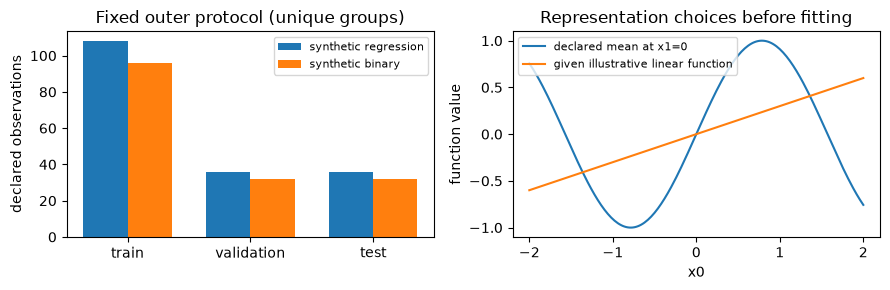

In [2]:
fig,axes = plt.subplots(1,2,figsize=(9,3))
demo_parts = np.arange(3)
axes[0].bar(demo_parts-.18,[108,36,36],width=.36,label='synthetic regression')
axes[0].bar(demo_parts+.18,[96,32,32],width=.36,label='synthetic binary')
axes[0].set(xticks=demo_parts,xticklabels=['train','validation','test'],ylabel='declared observations',title='Fixed outer protocol (unique groups)')
axes[0].legend(fontsize=8)
demo_axis = np.linspace(-2,2,201)
axes[1].plot(demo_axis,np.sin(2*demo_axis),label='declared mean at x1=0')
axes[1].plot(demo_axis,.3*demo_axis,label='given illustrative linear function')
axes[1].set(xlabel='x0',ylabel='function value',title='Representation choices before fitting')
axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

### Exercise 02.P.12 — Run the fixed selection study and inspect every candidate

**Type:** Experimental · **Answer:** Code

For each required dataset, create its outer group split, call the training/validation-only selector and record every fold score, pooled score, validation score, time and optimizer diagnostic. Verify the prescribed candidate counts and actual group/row sizes. Identify each validation champion before reading final test outcomes. Plot pooled training-CV scores and validation scores with family/configuration labels; do not plot a test leaderboard at this stage.

**Expected outcome:** actual selection records, retained unsuccessful tolerance flags, a frozen champion and no invented performance ranking.

In [ ]:
# Your code for Exercise 02.P.12.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.P.12**

The same candidate can have different diagnostics on different folds. Keep those records rather than replacing them with its final refit's status.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.P.12**

This depends on data, split and selection references. The code retains full raw evidence in bundles and prints concise selection summaries; the next checkpoint stores every fold record. These measurements characterize only this protocol. A failure to meet an optimization tolerance is reported and does not trigger hidden extra iterations.

~~~python
demo_benchmark_tasks = benchmark_datasets()
demo_benchmark_parts = {}; demo_benchmark_bundles = {}; demo_benchmark_times = {}
for name,data in demo_benchmark_tasks.items():
    parts = benchmark_partition(data['y'],data['groups'],data['task'])
    train,valid,test = parts; started = perf_counter()
    bundle = benchmark_select(data['X'][train],data['y'][train],data['groups'][train],
                              data['X'][valid],data['y'][valid],data['task'])
    demo_benchmark_times[name] = perf_counter()-started
    demo_benchmark_parts[name] = parts; demo_benchmark_bundles[name] = bundle
    print('Measured selection:',name,'outer row counts',[len(p) for p in parts],
          'CV fits',len(bundle['fold_records']),'seconds',demo_benchmark_times[name],
          'pooled scores',bundle['pooled_scores'].tolist(),'selected indices',bundle['selected_indices'],
          'validation records',bundle['validation_records'],'frozen champion',bundle['champion'])
assert len(demo_benchmark_bundles['regression']['fold_records']) == 30
assert len(demo_benchmark_bundles['iris']['fold_records']) == 42
fig,axes = plt.subplots(1,3,figsize=(12,3.5))
for axis,(name,bundle) in zip(axes,demo_benchmark_bundles.items()):
    records = bundle['validation_records']
    positions = np.arange(len(records))
    cv = [np.nan if r['family'] == 'baseline' else bundle['pooled_scores'][bundle['selected_indices'][r['family']]] for r in records]
    labels = ['baseline' if r['family'] == 'baseline' else f"{r['family']} #{bundle['selected_indices'][r['family']]}" for r in records]
    axis.bar(positions-.18,cv,width=.36,label='selected candidate CV')
    axis.bar(positions+.18,[r['score'] for r in records],width=.36,label='validation')
    axis.set(xticks=positions,xticklabels=labels,ylabel='unpenalized primary loss',title=name)
    axis.tick_params(axis='x',rotation=70,labelsize=7)
    axis.legend(fontsize=6)
fig.tight_layout(); plt.show()
~~~

</details>

### Exercise 02.P.13 — Save a numeric selection checkpoint and replay its arithmetic

**Type:** Programming · **Answer:** Code

Implement `benchmark_save_checkpoint`, `benchmark_load_checkpoint` and `benchmark_resume_checkpoint`. Save numeric split/fold/score arrays plus JSON protocol/diagnostic text, with no object arrays or pickle. Include a deterministic data-identity digest, candidate order and the frozen decision. Verify a round trip, reconstruct pooled scores and resume by fitting only the frozen training configurations. A checkpoint supports study resumption; it is not proof that its choices obeyed the protocol.

**Expected outcome:** safe numeric loading with `allow_pickle=False`, group-safe split/fold checks and reproducible selection arithmetic without accessing test outcomes.

In [ ]:
# Your code for Exercise 02.P.13.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.P.13**

Tree dictionaries need not be pickled. Save the deterministic fitting configuration and regenerate models from training only if a later session requires them.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.P.13**

This depends on the selector's bundle and split records. The digest identifies exact data bytes, including labels, without evaluating predictions; it is a version check, not model-selection feedback. Resume checks that identity and rebuilds models from training only, without repeating CV or validation selection. After final evaluation, save actual predictions/losses and update the selection checkpoint's used flag. If interrupted during final evaluation, treat the test as used and disclose any further access. These guards are study-protocol conventions, not adversarial access controls.

~~~python
import json
import hashlib
from pathlib import Path

def benchmark_data_digest(data):
    digest = hashlib.sha256()
    for key,dtype in (('X','float64'),('y','float64' if data['task'] == 'regression' else 'int64'),('groups','int64')):
        array = np.ascontiguousarray(data[key],dtype=np.dtype(dtype).newbyteorder('<'))
        digest.update(key.encode()); digest.update(str(array.shape).encode()); digest.update(array.tobytes())
    return digest.hexdigest()

def benchmark_save_checkpoint(path, bundle, partitions, data, dataset_name):
    groups = np.asarray(data['groups'])
    train,valid,test = (np.asarray(p,dtype=int) for p in partitions)
    assignment = np.full(len(train),-1,dtype=int)
    for fold,(_,held) in enumerate(bundle['folds']):
        assignment[held] = fold
    metadata = dict(dataset=dataset_name,data_digest=benchmark_data_digest(data),task=bundle['task'],specs=bundle['specs'],
                    selected=bundle['selected_indices'],champion=bundle['champion'],
                    fold_records=bundle['fold_records'],validation_records=bundle['validation_records'],
                    test_used=bundle['test_used'],outer_seed=242,fold_seed=243,fit_seed=244,
                    iris_member_sha256='6f608b71a7317216319b4d27b4d9bc84e6abd734eda7872b71a458569e2656c0')
    path = Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    np.savez_compressed(path,metadata=np.array(json.dumps(metadata,allow_nan=False)),
                        train_rows=train,validation_rows=valid,test_rows=test,groups=groups,
                        fold_assignment=assignment,pooled_scores=bundle['pooled_scores'])

def benchmark_load_checkpoint(path):
    with np.load(path,allow_pickle=False) as saved:
        result = {name:saved[name].copy() for name in saved.files}
    if any(array.dtype.hasobject for array in result.values()):
        raise ValueError('object arrays are not allowed')
    metadata = json.loads(str(result.pop('metadata').item()))
    parts = [result[name] for name in ('train_rows','validation_rows','test_rows')]
    groups = result['groups']
    if not np.array_equal(np.sort(np.concatenate(parts)),np.arange(len(groups))):
        raise ValueError('checkpoint partition must cover each row once')
    if any(np.intersect1d(groups[a],groups[b]).size for i,a in enumerate(parts) for b in parts[i+1:]):
        raise ValueError('checkpoint groups cross outer partitions')
    assignment = result['fold_assignment']; train = parts[0]
    if assignment.shape != train.shape or np.any(assignment < 0):
        raise ValueError('incomplete training fold assignment')
    if any(len(np.unique(assignment[groups[train] == group])) != 1 for group in np.unique(groups[train])):
        raise ValueError('checkpoint group crosses CV folds')
    return metadata,result

def benchmark_resume_checkpoint(path, data, fit_fn=benchmark_fit_model):
    metadata,arrays = benchmark_load_checkpoint(path)
    if metadata['test_used']:
        raise ValueError('final test was already used; analyze its saved evidence')
    if metadata['task'] != data['task'] or metadata['data_digest'] != benchmark_data_digest(data):
        raise ValueError('checkpoint data identity does not match')
    train = arrays['train_rows']; X,y = data['X'][train],data['y'][train]
    scaler = benchmark_scale_fit(X); A = benchmark_scale_apply(X,scaler)
    models = {}
    for family in ['baseline',*metadata['selected']]:
        spec = dict(family='baseline') if family == 'baseline' else metadata['specs'][metadata['selected'][family]]
        model = fit_fn(A,y,data['task'],spec,metadata['fit_seed'])
        models[family] = dict(model=model,scaler={key:value.copy() for key,value in scaler.items()},spec=dict(spec))
    assignment = arrays['fold_assignment']
    folds = [(np.flatnonzero(assignment != k),np.flatnonzero(assignment == k)) for k in np.unique(assignment)]
    return dict(task=data['task'],specs=metadata['specs'],folds=folds,fold_records=metadata['fold_records'],
                pooled_scores=arrays['pooled_scores'],selected_indices=metadata['selected'],models=models,
                validation_records=metadata['validation_records'],champion=metadata['champion'],frozen=True,test_used=False)

for name,bundle in demo_benchmark_bundles.items():
    path = Path('classical-checkpoints')/f'{name}-selection.npz'
    benchmark_save_checkpoint(path,bundle,demo_benchmark_parts[name],demo_benchmark_tasks[name],name)
    metadata,arrays = benchmark_load_checkpoint(path)
    assert metadata['champion'] == bundle['champion'] and not metadata['test_used']
    for candidate in range(len(metadata['specs'])):
        records = [r for r in metadata['fold_records'] if r['candidate'] == candidate]
        reconstructed = sum(r['loss_sum'] for r in records)/sum(r['held_rows'] for r in records)
        assert np.isclose(reconstructed,arrays['pooled_scores'][candidate])
    resumed = benchmark_resume_checkpoint(path,demo_benchmark_tasks[name])
    training_probe = demo_benchmark_tasks[name]['X'][arrays['train_rows'][:2]]
    for family in bundle['models']:
        original,resumed_record = bundle['models'][family],resumed['models'][family]
        a = benchmark_predict_model(original['model'],benchmark_scale_apply(training_probe,original['scaler']))
        b = benchmark_predict_model(resumed_record['model'],benchmark_scale_apply(training_probe,resumed_record['scaler']))
        np.testing.assert_allclose(a['prediction'],b['prediction'])
    demo_benchmark_bundles[name] = resumed
~~~

</details>

### Exercise 02.P.14 — Execute one frozen test batch and a paired group comparison

**Type:** Experimental · **Answer:** Code

Implement `benchmark_evaluate_once` and `benchmark_paired_group_interval`. After reviewing correctness and the frozen validation decision, evaluate the baseline and every frozen family winner in one test batch. Retain predictions and primary per-row losses, compute secondary metrics without inventing probabilities, and use 400 paired group resamples with seed 245 for the champion-minus-baseline sensitivity interval. Save numeric final evidence and analyze it without refitting.

**Expected outcome:** one guarded final pass, actual complete metric records, paired group resampling, resource accounting and a conclusion limited to these frozen procedures.

In [ ]:
# Your code for Exercise 02.P.14.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.P.14**

Resample group sums and sizes together. A row-weighted mean is a ratio of their total difference and total size, not an unweighted mean of group means.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.P.14**

These functions depend on earlier prediction and metric definitions. The in-memory guard prevents an accidental second final call in this session, while ordinary code outside the protocol could still inspect data. The interval describes a finite group-resampling sensitivity distribution conditional on fitted models and data; it is not a guaranteed population or post-selection confidence interval. When the baseline wins validation, its paired comparison with itself is zero by definition and must not be replaced by a more interesting test-selected competitor.

~~~python
def benchmark_evaluate_once(bundle, X, targets, predict_fn=benchmark_predict_model):
    if not bundle.get('frozen') or bundle.get('test_used'):
        raise ValueError('a frozen bundle may receive one final test evaluation')
    bundle['test_used'] = True
    results = {}
    for family,record in bundle['models'].items():
        started = perf_counter()
        A = benchmark_scale_apply(X,record['scaler'])
        output = predict_fn(record['model'],A)
        metrics = benchmark_metrics(targets,output,bundle['task'],record['model']['classes'])
        results[family] = dict(metrics=metrics,prediction=output['prediction'].copy(),
                               probability=output['probability'],log_probability=output['log_probability'],
                               losses=benchmark_primary_losses(targets,output['prediction'],bundle['task']),
                               seconds=perf_counter()-started)
    return results

def benchmark_paired_group_interval(differences, groups, repeats=400, seed=245):
    values = np.asarray(differences,dtype=float); groups = np.asarray(groups)
    if values.ndim != 1 or len(values) == 0 or groups.shape != values.shape or not np.isfinite(values).all() or not np.issubdtype(groups.dtype,np.integer):
        raise ValueError('finite paired differences and compatible integer groups required')
    if isinstance(repeats,(bool,np.bool_)) or not isinstance(repeats,(int,np.integer)) or not 1 <= repeats <= 10000:
        raise ValueError('integer resampling budget 1..10000 required')
    unique = np.unique(groups)
    sums = np.array([values[groups == g].sum() for g in unique]); sizes = np.array([np.sum(groups == g) for g in unique])
    rng = np.random.default_rng(seed); distribution = np.empty(repeats)
    for index in range(repeats):
        chosen = rng.integers(0,len(unique),size=len(unique))
        distribution[index] = sums[chosen].sum()/sizes[chosen].sum()
    return float(values.mean()),np.quantile(distribution,[.025,.975]),distribution

demo_benchmark_final = {}; demo_benchmark_intervals = {}
for name,bundle in demo_benchmark_bundles.items():
    data = demo_benchmark_tasks[name]; test = demo_benchmark_parts[name][2]
    started = perf_counter()
    final = benchmark_evaluate_once(bundle,data['X'][test],data['y'][test])
    difference = final[bundle['champion']]['losses']-final['baseline']['losses']
    mean,interval,distribution = benchmark_paired_group_interval(difference,data['groups'][test])
    demo_benchmark_final[name] = final; demo_benchmark_intervals[name] = (mean,interval)
    fields = dict(test_rows=test,groups=data['groups'][test],paired_distribution=distribution,
                  comparison=np.array([mean,*interval]),test_used=np.array(True),champion=np.array(bundle['champion']))
    for family,result in final.items():
        fields[f'{family}_prediction'] = result['prediction']; fields[f'{family}_losses'] = result['losses']
        if result['probability'] is not None:
            fields[f'{family}_probability'] = result['probability']; fields[f'{family}_log_probability'] = result['log_probability']
    np.savez_compressed(Path('classical-checkpoints')/f'{name}-final.npz',**fields)
    benchmark_save_checkpoint(Path('classical-checkpoints')/f'{name}-selection.npz',bundle,
                              demo_benchmark_parts[name],data,name)
    print('Measured frozen final panel:',name,'champion fixed by validation',bundle['champion'],
          'metrics',{family:result['metrics'] for family,result in final.items()},
          'champion-minus-baseline',mean,'conditional group sensitivity interval',interval.tolist(),
          'evaluation+resampling seconds',perf_counter()-started)
assert all(bundle['test_used'] for bundle in demo_benchmark_bundles.values())
~~~

</details>

## 7. Interpretation and critical analysis

### Bounded source and provenance study

Use the [UCI Iris source](https://archive.ics.uci.edu/dataset/53/iris), its bundled [attribution/provenance notice](../../src/ml_from_scratch/data/NOTICE.md), and the finite-family selection discussion in the preceding theory chapter. Audit the artifact actually used, its documented discrepancies, duplicate handling, assumptions and the scope of your final claim. The task does not reproduce Fisher's original experiment or establish a ranking on modern datasets.

### Exercise 02.P.15 — Defend the benchmark claim and identify selection reuse

**Type:** Critical · **Answer:** Markdown

Write a primary-source/protocol evidence table: exact data artifact and license, unchanged discrepancies, duplicate groups, split/CV decisions, candidate/work budgets, validation champion, final metrics and uncertainty limits. Explain what changes if the test panel motivates another model revision. Can the number of models printed in the final table be used as the full hypothesis-class count for a training-set guarantee?

**Expected outcome:** an evidence-backed bounded claim, an honest test-reuse policy and a rejected naive capacity argument.

**Your response to Exercise 02.P.15**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.P.15**

The learning procedures selected functions using training labels, and the family selection also used validation feedback. A final file count does not measure all eligible predictors.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.P.15**

The artifact hash, source DOI/license and unchanged bytes establish dataset identity, not population representativeness. Group boundaries and fold-local transformations establish specified procedural controls. Numerical oracles establish concrete implementation contracts. The single frozen test batch supports a comparison of the declared fitted procedures on that partition, with conditional group-resampling sensitivity. A revision informed by the test makes that partition development data and requires disclosing reuse and obtaining a new independent final evaluation for a fresh claim. The finite-family guarantee does not apply to training errors by counting only the final fitted model files; the procedures could have selected many functions from their full classes. State these limits alongside actual results rather than inventing a universal leaderboard conclusion.

</details>

### Exercise 02.P.16 — Explain a resource or convergence tradeoff without cherry-picking

**Type:** Critical · **Answer:** Markdown

A family has the best validation error but fails its selected optimization tolerance; another has a slightly worse error and runs much faster. Describe the predeclared decision rule used here and a separate bounded follow-up that could investigate the tradeoff. Which conclusions require another training/selection run, and which would contaminate a frozen test claim?

**Expected outcome:** actual unfinished-status reporting, named comparison criteria and separation between this fixed-budget result and a new study.

**Your response to Exercise 02.P.16**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.P.16**

The required protocol selects by validation primary error and reports diagnostics; it does not silently drop unfinished candidates or give them more work.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.P.16**

Retain both candidates and all their recorded diagnostics. Under this capstone's fixed rule, validation error chooses the family with ties in family order, while an unmet gap target limits any claim about its objective optimum. The report can state that this bounded-budget predictor achieved a measured error at a measured cost. A new predeclared study can compare gap targets, training budgets or Pareto tradeoffs using training/internal validation data; it is a different protocol and must retain unsuccessful runs. Do not use the frozen test panel to choose a new budget or family and still call that panel untouched. More work or a better solver may change prediction and runtime, so do not invent the outcome of that follow-up.

</details>

## 8. Review questions and knowledge checks

### Exercise 02.P.17 — Reconstruct one selection decision from its raw evidence

**Type:** Numerical · **Answer:** Markdown

Choose one actual family from your training-only CV table. Reconstruct each pooled candidate score from fold losses and sizes, apply its tie rule, and verify the validation champion comparison. Recompute one final paired mean from saved per-row losses without refitting anything. Explain why averaging all printed fold means blindly can change the chosen model.

**Expected outcome:** reproducible arithmetic tied to your own frozen numeric artifacts, with no fabricated reference result.

**Your response to Exercise 02.P.17**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.P.17**

Keep candidate order, fold sizes and task metric definitions alongside scores in the checkpoint.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.P.17**

For candidate $j$, the pooled score is $\sum_f n_f\bar\ell_{jf}/\sum_f n_f$. Apply the documented first-minimum rule, then compare the already refitted winners on validation only using their fixed family order. The final paired mean is the average of saved champion loss minus baseline loss on the same rows. Unequal group-derived folds can have different row counts, so an unweighted average estimates a different quantity. Your report should show actual arrays and arithmetic from the run. There is no universal numeric winner supplied for this open-ended evidence reconstruction, and no need to rerun final test inference to recompute its saved arithmetic.

</details>

### Exercise 02.P.18 — Present separate mathematics, implementation and research conclusions

**Type:** Conceptual · **Answer:** Markdown

Present your derivations, independent numerical checks, procedural isolation checks, actual selection/final records, resource measurements and bounded claim. Explain which mastery gates are satisfied and what remains unverified. Name one generalization, calibration, causal or optimization statement that your evidence does not support.

**Expected outcome:** completed explain/implement/verify/evaluate evidence and a report that clearly distinguishes exact facts from experimental conclusions.

**Your response to Exercise 02.P.18**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.P.18**

A passing notebook structure check is not a mathematical proof; a passing gradient test is not a statistical evaluation.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.P.18**

Mathematical evidence includes the stated objectives, gradients, covariance conventions and constraint derivations. Implementation evidence includes independent hand/finite-difference checks and group/fold/scaler audits. Experimental evidence includes every candidate budget/score/status, the validation decision, frozen final panel and named resource accounting. A supported claim identifies this task, artifact, protocol, metric and fitted procedures. Conditional resampling omits selection/training uncertainty; normalized probabilities do not prove calibration; feature importance is not causality; and a small validation error does not certify an unfinished optimizer. Acknowledge unsuccessful checks and unfinished evidence explicitly before declaring personal mastery.

</details>

## 9. Summary and next learning steps

The capstone combines representation, optimization, probability and evaluation under one reproducible protocol. Preserve all unsuccessful candidates and their work budgets, keep model answers separate from demonstrations, and use your report to distinguish mathematical correctness, implementation correctness and the supported experimental claim.

Submit your completed study notebook, source/version/seed record, frozen numeric checkpoints, all score tables, final conditional comparison, measured resources and report. Use resumable sessions for protocol/oracles, implementation, selection/freeze and final reporting. See the [project instructions](README.md) for self-checks and the [stage guide](../../notebooks/02-classical-ml/README.md) for measurements. Next is [Stage 03](../../notebooks/03-unsupervised-learning/README.md); existing Stage 04 neural-network chapters also remain usable under their stated prerequisites.